# Тема №1.1. Фильтрация изображений с использованием свертки в Python

В рамках практического занятия мы рассмотрим способы фильтрации
изображений с помощью 2D-свертки, представленной в виде функции
cv2.filter2D() в библиотеке OpenCV.



![Текст ссылки](https://media.proglib.io/wp-uploads/2018/06/1.gif)

Свертка происходит между исходным изображением и ядром. Ядро – это
еще один массив, который обычно меньше исходного изображения и
определяет действие фильтрации. Ядро может быть высокочастотным,
низкочастотным или настраиваемым, которое может обнаруживать
определенные функции в изображении.

![Текст ссылки](https://media.geeksforgeeks.org/wp-content/uploads/20211027142439/kernel-768x461.png)

![Текст ссылки](https://media.proglib.io/wp-uploads/2018/06/2.gif)

## Загрузка исходного изображения

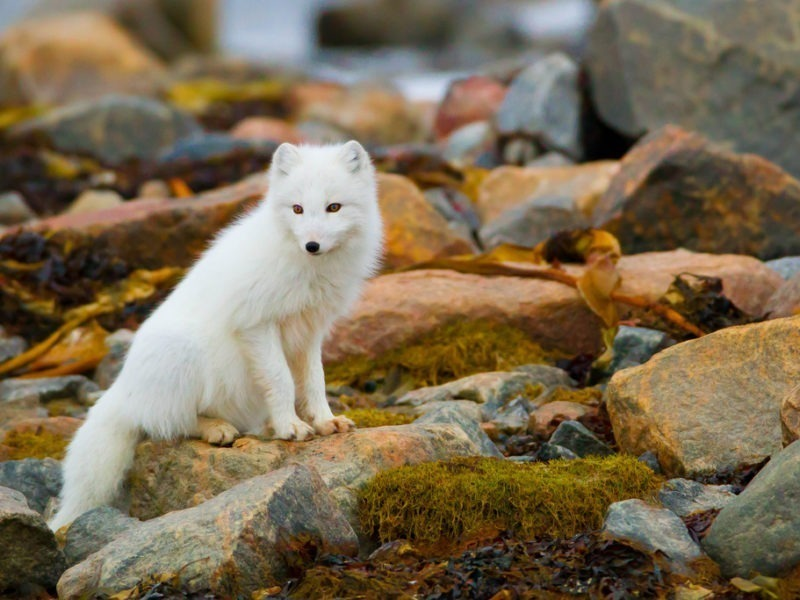

In [ ]:
# Импорт необходимых библиотек
import requests
from io import BytesIO
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

# Загрузка изображения из интернета
url = r'https://2spalnika.ru/wp-content/uploads/2022/12/zhivotniy-mir-hibin-800x600.jpg'

# HTTP запрос с потоковой загрузкой для экономии памяти
resp = requests.get(url, stream=True).raw

# Преобразование байтового потока в массив NumPy
img_bytes = np.asarray(bytearray(resp.read()), dtype="uint8")

# Декодирование в цветное изображение BGR
img_src = cv2.imdecode(img_bytes, cv2.IMREAD_COLOR)

cv2_imshow(img_src)

In [ ]:
import cv2
import numpy as np

def image_to_csv(img, csv_path="output_image.csv"):
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_resized = cv2.resize(img_gray, (img_gray.shape[0] // 5, img_gray.shape[1] // 5), interpolation=cv2.INTER_AREA)
    np.savetxt(csv_path, img_resized, fmt='%d', delimiter=',')

image_to_csv(img_src)

## Виды фильтров

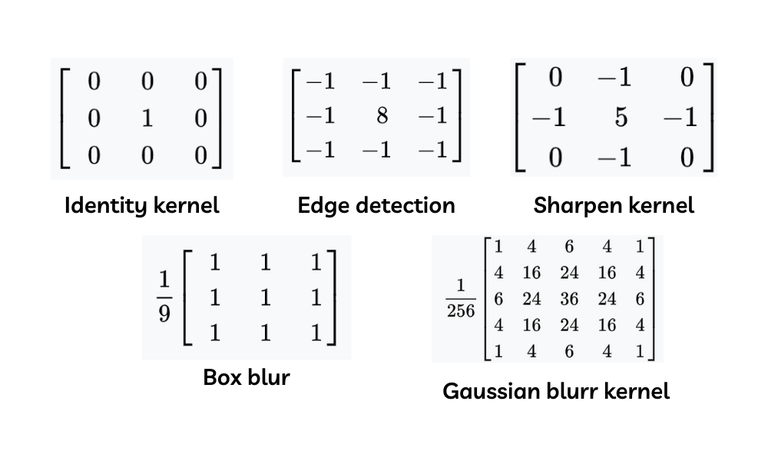

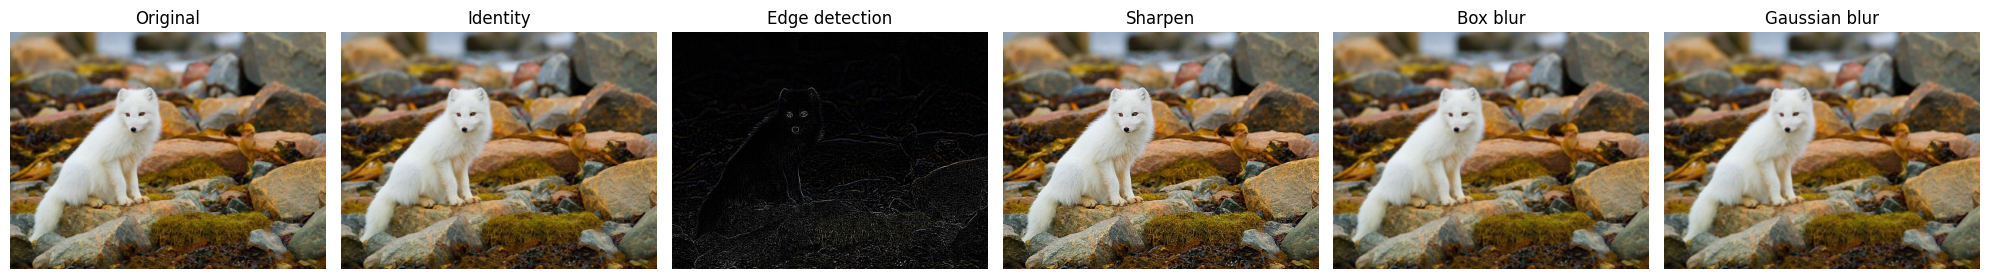

In [ ]:
# Определение ядер фильтров
kernels = {
    'Original': None,  # Исходное изображение
    'Identity': np.array([[0, 0, 0],
                          [0, 1, 0],
                          [0, 0, 0]]),

    'Edge detection': np.array([[-1, -1, -1],
                                [-1, 8, -1],
                                [-1, -1, -1]]),

    'Sharpen': np.array([[0, -1, 0],
                         [-1, 5, -1],
                         [0, -1, 0]]),

    'Box blur': (1/9) * np.array([[1, 1, 1],
                                  [1, 1, 1],
                                  [1, 1, 1]]),

    'Gaussian blur': (1/256) * np.array([
        [1, 4, 6, 4, 1],
        [4, 16, 24, 16, 4],
        [6, 24, 36, 24, 6],
        [4, 16, 24, 16, 4],
        [1, 4, 6, 4, 1]
    ])
}

# Применение всех фильтров и сохранение результатов
results = {}
for name, kernel in kernels.items():
    if kernel is None:
        # Исходное изображение
        results[name] = img_src.copy()
    else:
        # Применение фильтра
        results[name] = cv2.filter2D(img_src, -1, kernel)

# Общий обзор всех результатов в одной строке
fig, axes = plt.subplots(1, len(kernels), figsize=(20, 4))
for idx, (name, img) in enumerate(results.items()):
    # Преобразование BGR в RGB для корректного отображения в matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[idx].imshow(img_rgb)
    axes[idx].set_title(name, fontsize=12)
    axes[idx].axis('off')  # Убираем оси координат

plt.tight_layout()
plt.show()

#### **Описание принципов работы ядер фильтрации:**


- **Identity kernel (Единичное ядро)** представляет собой нейтральный фильтр, который не изменяет исходное изображение. Центральный элемент равен единице, а остальные - нулю, что означает прямую передачу значения центрального пикселя без учета соседних. Этот фильтр используется как эталонное ядро для тестирования алгоритмов свертки или как базовая точка отсчета при разработке других фильтров.



```python
    'Identity': np.array([[0, 0, 0],
                          [0, 1, 0],
                          [0, 0, 0]]),
```



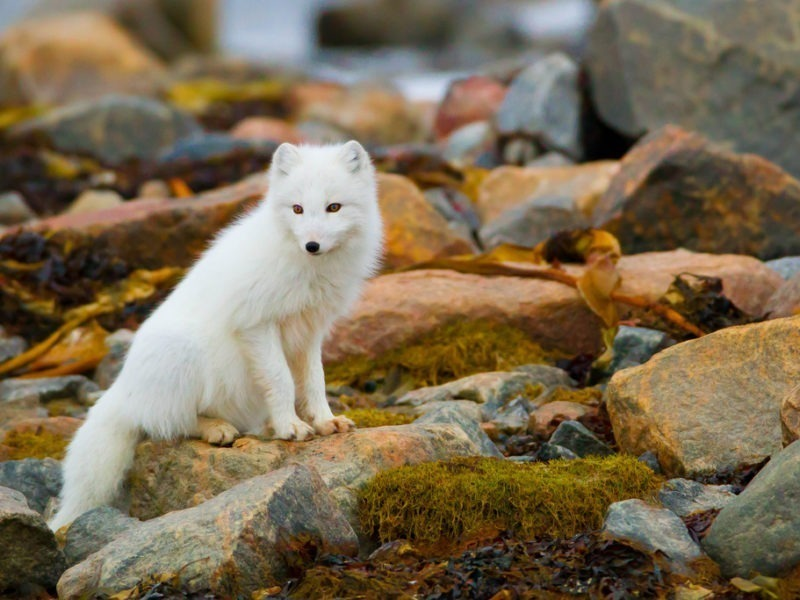

In [ ]:
cv2_imshow(results['Identity'])

- **Edge detection (Детектор границ)** является классическим фильтром высоких частот, который усиливает резкие переходы яркости между соседними пикселями. Отрицательные коэффициенты по краям ядра вычитают значения соседних пикселей из центрального, умноженного на 8. Результат дает высокую амплитуду в местах значительных градиентов яркости, эффективно выделяя контуры объектов на изображении.



```python
    'Edge detection': np.array([[-1, -1, -1],
                                [-1, 8, -1],
                                [-1, -1, -1]]),
```



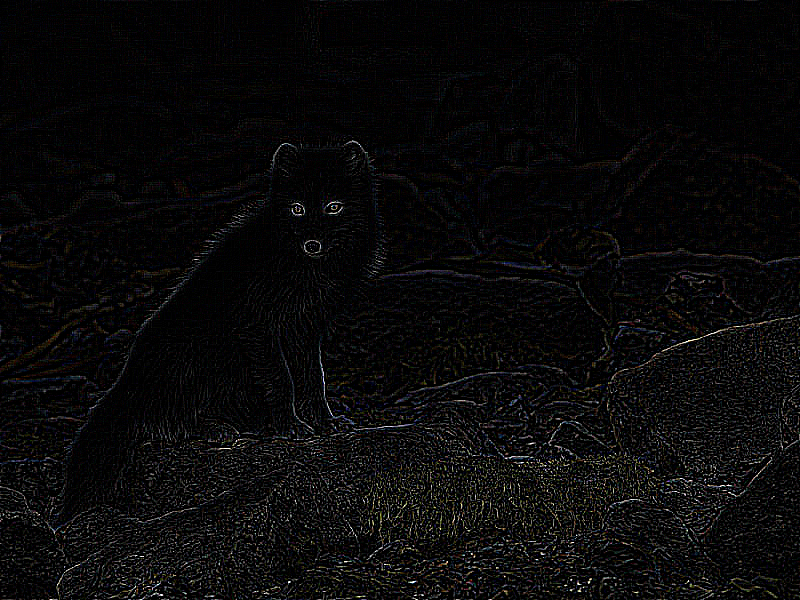

In [ ]:
cv2_imshow(results['Edge detection'])

- **Sharpen kernel (Ядро повышения резкости)** работает по принципу усиления высокочастотных компонентов изображения. Центральный коэффициент 5 усиливает исходный пиксель, а отрицательные значения (-1) по краям вычитают яркость соседних пикселей, создавая эффект повышения контрастности на границах. Это приводит к визуальному увеличению четкости деталей без изменения общей структуры изображения.




```python
    'Sharpen': np.array([[0, -1, 0],
                         [-1, 5, -1],
                         [0, -1, 0]]),
```



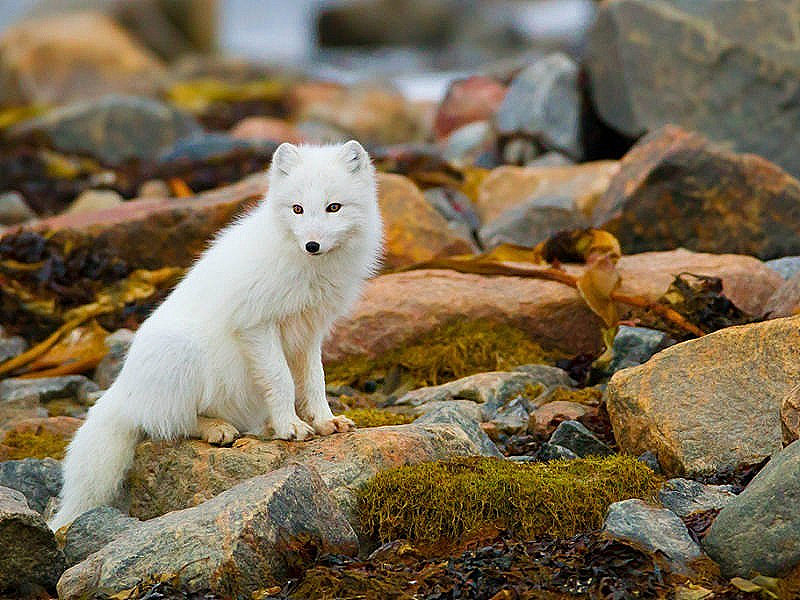

In [ ]:
cv2_imshow(results['Sharpen'])

- **Box blur (Прямоугольное размытие)** представляет простейший фильтр низких частот, основанный на равномерном усреднении значений пикселей в окрестности 3×3. Все коэффициенты ядра равны 1/9, что обеспечивает одинаковый вклад каждого соседнего пикселя в результирующее значение. Такое усреднение подавляет высокочастотные шумы и создает равномерное размытие изображения.



```python
    'Box blur': (1/9) * np.array([[1, 1, 1],
                                  [1, 1, 1],
                                  [1, 1, 1]]),
```



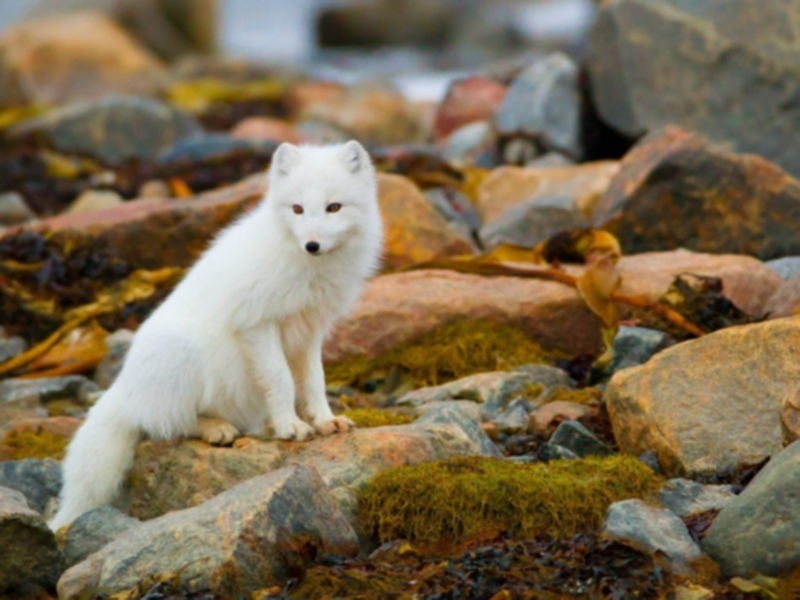

In [ ]:
cv2_imshow(results['Box blur'])

- **Gaussian blur kernel (Гауссово размытие)** является более сложным фильтром низких частот, использующим весовые коэффициенты, распределенные по гауссовой кривой. Центральные элементы имеют больший вес, а периферийные - меньший, что создает более естественное размытие по сравнению с прямоугольным фильтром. Размер ядра 5×5 и нормировка коэффициентов обеспечивают плавное подавление высоких частот с сохранением естественности изображения.



```python
    'Gaussian blur': (1/256) * np.array([
        [1, 4, 6, 4, 1],
        [4, 16, 24, 16, 4],
        [6, 24, 36, 24, 6],
        [4, 16, 24, 16, 4],
        [1, 4, 6, 4, 1]
    ])
```



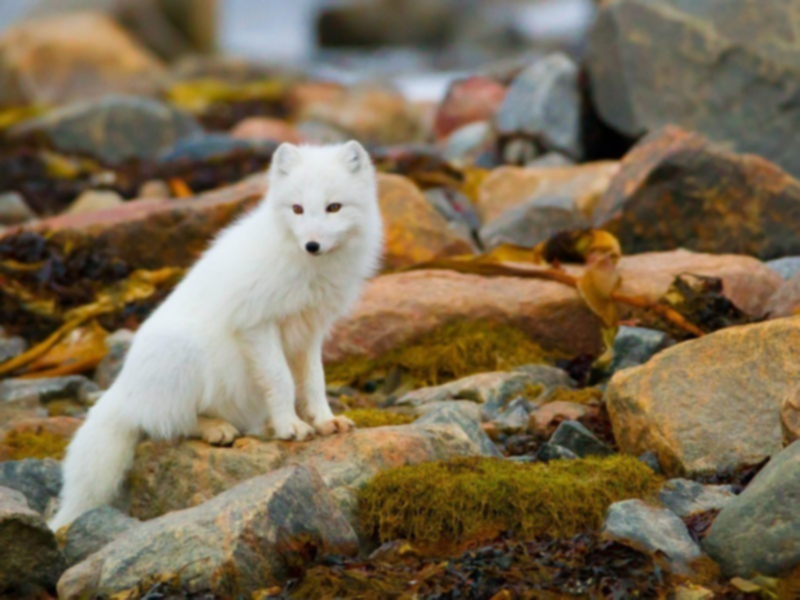

In [ ]:
cv2_imshow(results['Gaussian blur'])

**Матрица свертки** в каждом случае определяет характер математической операции, при которой значение каждого пикселя результирующего изображения вычисляется как взвешенная сумма исходного пикселя и его соседей, где веса задаются элементами ядра фильтра.